In [ ]:
!pip install transformers accelerate datasets torchaudio librosa tqdm

In [ ]:
import zipfile
import os

# SAVEEE zip file
saveee_zip_path = "/content/saveee.zip"

# Output folder
saveee_output_folder = "/content/SAVEEE_DATA"

# Create folder
os.makedirs(saveee_output_folder, exist_ok=True)

# Extract zip
with zipfile.ZipFile(saveee_zip_path, "r") as zip_ref:
    zip_ref.extractall(saveee_output_folder)

print("SAVEEE Dataset Extracted Successfully!")
print("Contents:", os.listdir(saveee_output_folder))

SAVEEE Dataset Extracted Successfully!
Contents: ['audiodata', 'AudioData']


In [ ]:
import glob

saveee_wavs = glob.glob("/content/SAVEEE_DATA/**/*.wav", recursive=True)

print("Total SAVEEE WAV Files:", len(saveee_wavs))
print("Sample File:", saveee_wavs[0])

Total SAVEEE WAV Files: 960
Sample File: /content/SAVEEE_DATA/audiodata/AudioData/DC/sa05.wav


In [ ]:
import zipfile
import os

# CRAMA-D zip file
crama_zip_path = "/content/crama-d.zip"

# Output folder
crama_output_folder = "/content/CRAMA-D_DATA"

# Create folder
os.makedirs(crama_output_folder, exist_ok=True)

# Extract zip
with zipfile.ZipFile(crama_zip_path, "r") as zip_ref:
    zip_ref.extractall(crama_output_folder)

print("CRAMA-D Dataset Extracted Successfully!")
print("Contents:", os.listdir(crama_output_folder))

CRAMA-D Dataset Extracted Successfully!
Contents: ['AudioWAV']


In [ ]:
crama_wavs = glob.glob("/content/CRAMA-D_DATA/**/*.wav", recursive=True)

print("Total CRAMA-D WAV Files:", len(crama_wavs))
print("Sample File:", crama_wavs[0])

Total CRAMA-D WAV Files: 7442
Sample File: /content/CRAMA-D_DATA/AudioWAV/1002_TIE_HAP_XX.wav


In [ ]:
import os, glob
import numpy as np
import pandas as pd
import librosa
import torch

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from datasets import Dataset

from transformers import (
    Wav2Vec2Processor,
    Wav2Vec2ForSequenceClassification,
    TrainingArguments,
    Trainer
)

import warnings
warnings.filterwarnings("ignore")

print("Transformers Version:", __import__("transformers").__version__)
print("GPU Available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))

Transformers Version: 5.0.0
GPU Available: True
GPU Name: Tesla T4


In [ ]:
savee_files = glob.glob("/content/SAVEEE_DATA/**/*.wav", recursive=True)
crema_files = glob.glob("/content/CRAMA-D_DATA/**/*.wav", recursive=True)

paths = savee_files + crema_files

print("Total SAVEE Files:", len(savee_files))
print("Total CREMA Files:", len(crema_files))
print("Total Combined Files:", len(paths))

Total SAVEE Files: 960
Total CREMA Files: 7442
Total Combined Files: 8402


In [ ]:
def get_savee_label(file):
    name = file.split("/")[-1]
    if "_" in name:
        emotion_part = name.split("_")[1]
    else:
        emotion_part = name

    if emotion_part.startswith("a"): return "angry"
    if emotion_part.startswith("d"): return "disgust"
    if emotion_part.startswith("f"): return "fear"
    if emotion_part.startswith("h"): return "happy"
    if emotion_part.startswith("n"): return "neutral"
    if emotion_part.startswith("sa"): return "sad"
    if emotion_part.startswith("su"): return "surprise"
    return "unknown"


def get_crema_label(file):
    parts = file.split("/")[-1].split("_")
    if len(parts) < 3:
        return "unknown"
    emotion_code = parts[2]

    mapping = {
        "ANG": "angry",
        "DIS": "disgust",
        "FEA": "fear",
        "HAP": "happy",
        "NEU": "neutral",
        "SAD": "sad"
    }
    return mapping.get(emotion_code, "unknown")

In [ ]:
labels = []
for file in paths:
    if "SAVEEE_DATA" in file:
        labels.append(get_savee_label(file))
    else:
        labels.append(get_crema_label(file))

df = pd.DataFrame({"path": paths, "label": labels})
df = df[df["label"] != "unknown"]

print(df["label"].value_counts())
print("df created successfully")

label
sad         1391
angry       1391
happy       1391
disgust     1391
fear        1391
neutral     1327
surprise     120
Name: count, dtype: int64
df created successfully


In [ ]:
df = df.groupby("label").sample(1200, replace=True)
print("Balanced Dataset Count:\n")
print(df["label"].value_counts())

Balanced Dataset Count:

label
angry       1200
disgust     1200
fear        1200
happy       1200
neutral     1200
sad         1200
surprise    1200
Name: count, dtype: int64


In [ ]:
encoder = LabelEncoder()
df["label_id"] = encoder.fit_transform(df["label"])

num_labels = len(encoder.classes_)
print("Emotion Classes:", encoder.classes_)
print("num_labels:", num_labels)

Emotion Classes: ['angry' 'disgust' 'fear' 'happy' 'neutral' 'sad' 'surprise']
num_labels: 7


In [ ]:
train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["label_id"]
)

train_dataset = Dataset.from_pandas(train_df)
test_dataset = Dataset.from_pandas(test_df)

print("Train Size:", len(train_dataset))
print("Test Size:", len(test_dataset))

Train Size: 6720
Test Size: 1680


In [ ]:
processor = Wav2Vec2Processor.from_pretrained("facebook/wav2vec2-base")
print("Processor Loaded")

preprocessor_config.json:   0%|          | 0.00/159 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/163 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/291 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/85.0 [00:00<?, ?B/s]

Processor Loaded


In [ ]:
def preprocess(batch):
    audio, sr = librosa.load(batch["path"], sr=16000)
    inputs = processor(audio, sampling_rate=16000)
    batch["input_values"] = inputs["input_values"][0]
    batch["labels"] = batch["label_id"]
    return batch

train_dataset = train_dataset.map(preprocess)
test_dataset = test_dataset.map(preprocess)

print("Preprocessing Done")

Map:   0%|          | 0/6720 [00:00<?, ? examples/s]

Map:   0%|          | 0/1680 [00:00<?, ? examples/s]

Preprocessing Done


In [ ]:
def collate_fn(batch):
    input_values = [torch.tensor(item["input_values"]) for item in batch]
    labels = torch.tensor([item["labels"] for item in batch])

    input_values = torch.nn.utils.rnn.pad_sequence(
        input_values,
        batch_first=True,
        padding_value=0.0
    )

    return {"input_values": input_values, "labels": labels}

In [ ]:
def preprocess(batch):
    audio, sr = librosa.load(batch["path"], sr=16000)

    processed = processor(
        audio,
        sampling_rate=16000,
        padding=True,
        truncation=True,
        max_length=16000 * 6   # 6 seconds instead of 3
    )

    batch["input_values"] = processed["input_values"][0]
    batch["labels"] = int(batch["label_id"])

    return batch

In [ ]:
train_dataset = train_dataset.remove_columns(
    [col for col in train_dataset.column_names if col not in ["input_values", "labels"]]
)

test_dataset = test_dataset.remove_columns(
    [col for col in test_dataset.column_names if col not in ["input_values", "labels"]]
)

print("Extra columns removed")

Extra columns removed


In [ ]:
print("Train columns:", train_dataset.column_names)
print("Test columns:", test_dataset.column_names)
print(f"Train size: {len(train_dataset)}")
print(f"Test size: {len(test_dataset)}")

Train columns: ['input_values', 'labels']
Test columns: ['input_values', 'labels']
Train size: 6720
Test size: 1680


In [ ]:
model = Wav2Vec2ForSequenceClassification.from_pretrained(
    "facebook/wav2vec2-base",
    num_labels=num_labels
)

model.freeze_feature_encoder()
print("Model Loaded + Feature Encoder Frozen")

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

Wav2Vec2ForSequenceClassification LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     | 
-----------------------------+------------+-
quantizer.weight_proj.weight | UNEXPECTED | 
quantizer.weight_proj.bias   | UNEXPECTED | 
project_hid.bias             | UNEXPECTED | 
project_hid.weight           | UNEXPECTED | 
quantizer.codevectors        | UNEXPECTED | 
project_q.bias               | UNEXPECTED | 
project_q.weight             | UNEXPECTED | 
projector.weight             | MISSING    | 
classifier.bias              | MISSING    | 
projector.bias               | MISSING    | 
classifier.weight            | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model Loaded + Feature Encoder Frozen


In [ ]:
model.gradient_checkpointing_enable()

In [ ]:
training_args = TrainingArguments(
    output_dir="./wav2vec2-ser",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=1e-5,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    num_train_epochs=16,
    warmup_steps=200,
    weight_decay=0.01,
    logging_strategy="epoch",
    report_to="none",
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    save_total_limit=2
)

In [ ]:
def compute_metrics(pred):
    logits, labels = pred
    preds = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(labels, preds)}

In [ ]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    data_collator=collate_fn,
    compute_metrics=compute_metrics
)

print("Trainer Ready")

Trainer Ready


In [ ]:
from transformers import TrainerCallback

class GradualUnfreezeCallback(TrainerCallback):
    def on_epoch_end(self, args, state, control, **kwargs):

        # Stage 1: unfreeze feature extractor
        if int(state.epoch) == 3:
            model.wav2vec2.feature_extractor._freeze_parameters = False
            print("Feature extractor unfrozen (epoch 3)")

        # Stage 2: unfreeze full encoder
        if int(state.epoch) == 6:
            for param in model.wav2vec2.parameters():
                param.requires_grad = True
            print("Full encoder unfrozen (epoch 6)")

trainer.add_callback(GradualUnfreezeCallback())

In [ ]:
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy
1,1.337606,0.908970,0.713690
2,0.755486,0.775015,0.748810
3,0.619925,0.645959,0.812500
4,0.536478,0.752004,0.826786
5,0.467502,0.636106,0.858929
6,0.400305,0.882759,0.821429
7,0.318614,0.678514,0.883333
8,0.313060,0.665250,0.891667
9,0.285438,0.668433,0.892262
10,0.220756,0.660362,0.900595


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Feature extractor unfrozen (epoch 3)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (10 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=26880, training_loss=0.3779017374629066, metrics={'train_runtime': 13889.7216, 'train_samples_per_second': 7.741, 'train_steps_per_second': 1.935, 'total_flos': 3.668674397284799e+18, 'train_loss': 0.3779017374629066, 'epoch': 16.0})

In [ ]:
results = trainer.evaluate()
print("Final Accuracy:", results["eval_accuracy"] * 100, "%")

Final Accuracy: 90.77380952380952 %


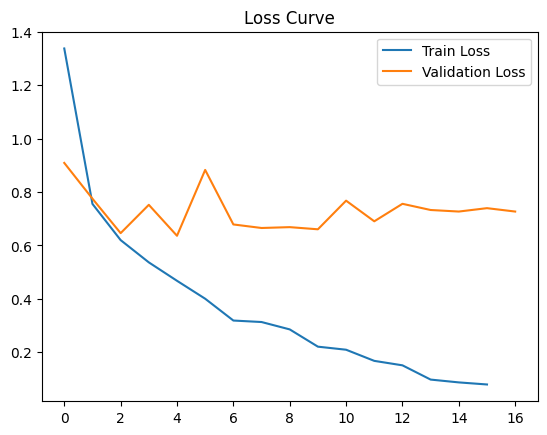

In [ ]:
import matplotlib.pyplot as plt

history = trainer.state.log_history

train_loss = []
eval_loss = []
eval_acc = []

for log in history:
    if "loss" in log and "epoch" in log:
        train_loss.append(log["loss"])
    if "eval_loss" in log:
        eval_loss.append(log["eval_loss"])
    if "eval_accuracy" in log:
        eval_acc.append(log["eval_accuracy"])

plt.figure()
plt.plot(train_loss, label="Train Loss")
plt.plot(eval_loss, label="Validation Loss")
plt.legend()
plt.title("Loss Curve")
plt.show()

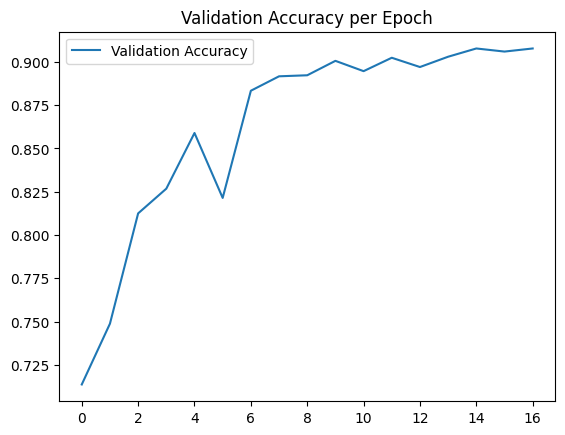

In [ ]:
plt.figure()
plt.plot(eval_acc, label="Validation Accuracy")
plt.legend()
plt.title("Validation Accuracy per Epoch")
plt.show()

              precision    recall  f1-score   support

       angry       0.90      0.94      0.92       240
     disgust       0.92      0.87      0.89       240
        fear       0.86      0.85      0.86       240
       happy       0.94      0.86      0.90       240
     neutral       0.90      0.96      0.93       240
         sad       0.84      0.88      0.86       240
    surprise       1.00      1.00      1.00       240

    accuracy                           0.91      1680
   macro avg       0.91      0.91      0.91      1680
weighted avg       0.91      0.91      0.91      1680



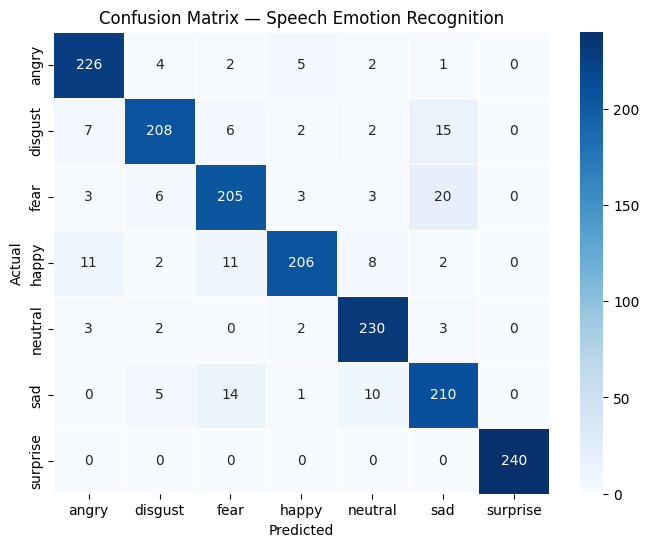

In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

predictions = trainer.predict(test_dataset)
y_pred = np.argmax(predictions.predictions, axis=1)
y_true = predictions.label_ids

print(classification_report(y_true, y_pred, target_names=encoder.classes_))

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8,6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=encoder.classes_,
    yticklabels=encoder.classes_,
    linewidths=0.5,
    linecolor="white"
)

plt.title("Confusion Matrix — Speech Emotion Recognition")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

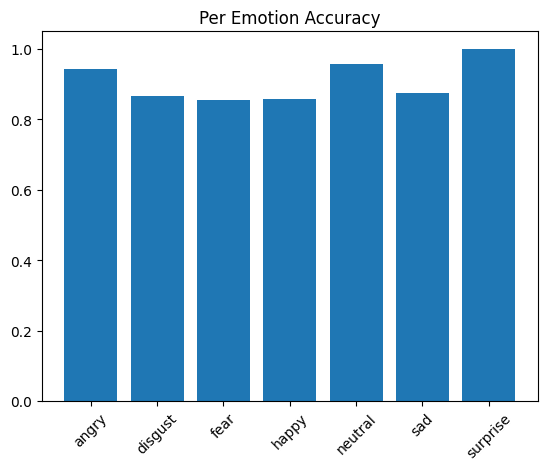

In [ ]:
per_emotion_acc = cm.diagonal() / cm.sum(axis=1)

plt.figure()
plt.bar(encoder.classes_, per_emotion_acc)
plt.xticks(rotation=45)
plt.title("Per Emotion Accuracy")
plt.show()

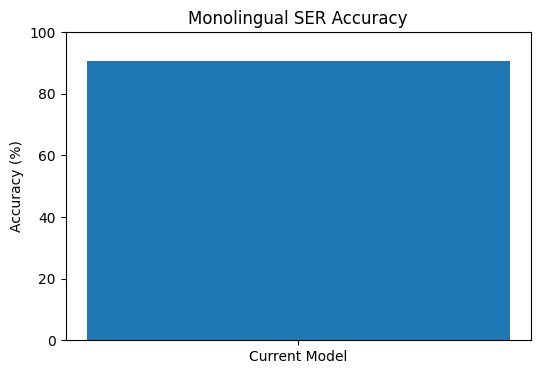

In [ ]:
mono_acc = results["eval_accuracy"] * 100

plt.figure(figsize=(6,4))
plt.bar(["Current Model"], [mono_acc])
plt.ylabel("Accuracy (%)")
plt.title("Monolingual SER Accuracy")
plt.ylim(0,100)
plt.show()

In [ ]:
import joblib

# Save trained wav2vec model
trainer.save_model("/content/monolingual_wav2vec2_model")

# Save processor
processor.save_pretrained("/content/monolingual_processor")

# Save label encoder
joblib.dump(encoder, "/content/label_encoder_mono.pkl")

print("Monolingual model saved locally")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Monolingual model saved locally


In [ ]:
import json

mono_results = trainer.evaluate()

with open("/content/monolingual_metrics.json", "w") as f:
    json.dump(mono_results, f)

print("Monolingual metrics saved")

Monolingual metrics saved


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!cp -r /content/monolingual_wav2vec2_model /content/drive/MyDrive/
!cp -r /content/monolingual_processor /content/drive/MyDrive/
!cp /content/label_encoder_mono.pkl /content/drive/MyDrive/
!cp /content/monolingual_metrics.json /content/drive/MyDrive/
!cp /content/monolingual_accuracy.png /content/drive/MyDrive/

print("Monolingual progress backed up to Drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
cp: cannot stat '/content/monolingual_wav2vec2_model': No such file or directory
cp: cannot stat '/content/monolingual_processor': No such file or directory
cp: cannot stat '/content/label_encoder_mono.pkl': No such file or directory
cp: cannot stat '/content/monolingual_metrics.json': No such file or directory
cp: cannot stat '/content/monolingual_accuracy.png': No such file or directory
Monolingual progress backed up to Drive


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from transformers import Wav2Vec2ForSequenceClassification, Wav2Vec2Processor
import joblib

model = Wav2Vec2ForSequenceClassification.from_pretrained(
    "/content/drive/MyDrive/monolingual_wav2vec2_model"
)

processor = Wav2Vec2Processor.from_pretrained(
    "/content/drive/MyDrive/monolingual_processor"
)

encoder = joblib.load("/content/drive/MyDrive/label_encoder_mono.pkl")

print("Monolingual model restored successfully")

Loading weights:   0%|          | 0/215 [00:00<?, ?it/s]

Monolingual model restored successfully


In [ ]:
print(model.config.num_labels)

7


In [ ]:
model.config.use_cache = False
print("Low-memory attention enabled")

Low-memory attention enabled


In [ ]:
!ls -lh /content

total 238M
-rw-r--r-- 1 root root 105M Feb 28 12:10 crama-d.zip
drwx------ 5 root root 4.0K Feb 28 12:09 drive
drwxr-xr-x 1 root root 4.0K Feb  6 14:31 sample_data
-rw-r--r-- 1 root root 132M Feb 28 12:10 saveee.zip


In [ ]:
!rm -rf /content/subo.zip
!rm -rf /content/SUBESCO
!rm -rf /content/SUBESCO_BANGLA_DATA

In [ ]:
!pip install -q kaggle

print("✓ Kaggle API installed")


✓ Kaggle API installed


In [ ]:
import os
import json

# Your API credentials
kaggle_credentials = {
    "username": "aritra71",
    "key": "KGAT_0664cecbb907758541fd29811fbd651d"
}

# Create .kaggle directory
os.makedirs('/root/.kaggle', exist_ok=True)

# Write kaggle.json
kaggle_json_path = '/root/.kaggle/kaggle.json'
with open(kaggle_json_path, 'w') as f:
    json.dump(kaggle_credentials, f)

# Set correct permissions
os.chmod(kaggle_json_path, 0o600)

print("="*70)
print("KAGGLE API CONFIGURED")
print("="*70)
print("✓ kaggle.json created successfully")
print(f"✓ Location: {kaggle_json_path}")
print(f"✓ Permissions: 600 (secure)")
print("="*70)

# Verify
if os.path.exists(kaggle_json_path):
    print("\n✓ Configuration verified - ready to download!")
else:
    print("\n Error: kaggle.json not created")

KAGGLE API CONFIGURED
✓ kaggle.json created successfully
✓ Location: /root/.kaggle/kaggle.json
✓ Permissions: 600 (secure)

✓ Configuration verified - ready to download!


In [ ]:
print("="*70)
print("DOWNLOADING SUBESCO-BANGLA FROM KAGGLE")
print("="*70)

# Download
print("\nDownloading dataset...")
print("This may take 2-5 minutes depending on your connection")

!kaggle datasets download -d sushmit0109/subescobangla-speech-emotion-dataset

print("\n✓ Download complete!")

# Verify downloaded file
import os
downloaded_files = [f for f in os.listdir('.') if f.endswith('.zip')]

if downloaded_files:
    zip_file = downloaded_files[0]
    file_size_mb = os.path.getsize(zip_file) / (1024 * 1024)
    print(f"\n✓ Downloaded: {zip_file}")
    print(f"  Size: {file_size_mb:.1f} MB")
else:
    print("\n No zip file found - download may have failed")
    print("Check error messages above")

print("="*70)

DOWNLOADING SUBESCO-BANGLA FROM KAGGLE

This may take 2-5 minutes depending on your connection
Dataset URL: https://www.kaggle.com/datasets/sushmit0109/subescobangla-speech-emotion-dataset
License(s): CC-BY-NC-SA-4.0
 99% 1.54G/1.55G [00:08<00:00, 77.9MB/s]
100% 1.55G/1.55G [00:09<00:00, 178MB/s] 

✓ Download complete!

✓ Downloaded: subescobangla-speech-emotion-dataset.zip
  Size: 1588.8 MB


In [ ]:
import zipfile
import os

# Find the downloaded zip file
zip_files = [f for f in os.listdir('.') if 'subesco' in f.lower() and f.endswith('.zip')]

if not zip_files:
    print("Zip file not found!")
    print("Available files:")
    !ls -lh *.zip
else:
    zip_filename = zip_files[0]
    print(f"✓ Found: {zip_filename}")

    # Create extraction directory
    extract_dir = "/content/SUBESCO_BANGLA"
    os.makedirs(extract_dir, exist_ok=True)

    print("\n" + "="*70)
    print("EXTRACTING DATASET")
    print("="*70)
    print("This may take 2-5 minutes...")

    # Extract
    with zipfile.ZipFile(zip_filename, 'r') as zip_ref:
        # Show progress
        files_to_extract = zip_ref.namelist()
        print(f"Extracting {len(files_to_extract)} files...")
        zip_ref.extractall(extract_dir)

    print("✓ Extraction complete!")

    # Show directory structure
    print("\n" + "="*70)
    print("DIRECTORY STRUCTURE")
    print("="*70)

    for root, dirs, files in os.walk(extract_dir):
        level = root.replace(extract_dir, '').count(os.sep)
        if level < 3:  # Show first 3 levels
            indent = '  ' * level
            folder_name = os.path.basename(root) if os.path.basename(root) else 'SUBESCO_BANGLA'
            print(f'{indent} {folder_name}/')

            if level < 2:
                subindent = '  ' * (level + 1)
                # Show first 5 files
                for i, file in enumerate(files[:5]):
                    print(f'{subindent} {file}')
                if len(files) > 5:
                    print(f'{subindent}... and {len(files)-5} more files')

    print("="*70)

✓ Found: subescobangla-speech-emotion-dataset.zip

EXTRACTING DATASET
This may take 2-5 minutes...
Extracting 7000 files...
✓ Extraction complete!

DIRECTORY STRUCTURE
 SUBESCO_BANGLA/
   SUBESCO/
     F_09_CHAITY_S_8_HAPPY_4.wav
     M_03_ILIAS_S_10_FEAR_3.wav
     F_10_FAHMEE_S_5_FEAR_1.wav
     M_08_PRASUN_S_6_FEAR_2.wav
     M_04_BIBHAS_S_2_SAD_3.wav
    ... and 6995 more files


In [ ]:
import glob
import os

print("="*70)
print("SEARCHING FOR AUDIO FILES")
print("="*70)

# Search for audio files
audio_files_bn = []
search_patterns = [
    '*.wav', '*.WAV',
    '*.mp3', '*.MP3',
    '*.flac', '*.FLAC',
    '*.m4a', '*.M4A'
]

print("\nSearching in: /content/SUBESCO_BANGLA/")
for pattern in search_patterns:
    found = glob.glob(f"/content/SUBESCO_BANGLA/**/{pattern}", recursive=True)
    if found:
        print(f"  ✓ Found {len(found):4d} {pattern} files")
        audio_files_bn.extend(found)

# Remove duplicates (if any)
audio_files_bn = list(set(audio_files_bn))

print("\n" + "="*70)
print("BENGALI DATASET SUMMARY")
print("="*70)
print(f"Total audio files: {len(audio_files_bn)}")

if len(audio_files_bn) > 0:
    print(f"\n Sample files:")
    for i, filepath in enumerate(audio_files_bn[:5]):
        filename = os.path.basename(filepath)
        size_kb = os.path.getsize(filepath) / 1024
        print(f"  {i+1}. {filename} ({size_kb:.1f} KB)")

    if len(audio_files_bn) > 5:
        print(f"  ... and {len(audio_files_bn)-5} more files")

    # Calculate statistics
    total_size_mb = sum(os.path.getsize(f) for f in audio_files_bn) / (1024*1024)
    avg_size_kb = (total_size_mb * 1024) / len(audio_files_bn)

    print(f"\n Statistics:")
    print(f"  Total size: {total_size_mb:.1f} MB")
    print(f"  Average file size: {avg_size_kb:.1f} KB")

    # Verify one file can be loaded
    print(f"\n Verifying file accessibility...")
    try:
        import librosa
        test_audio, test_sr = librosa.load(audio_files_bn[0], sr=16000, duration=1)
        print(f"  ✓ Successfully loaded test file")
        print(f"  ✓ Sample rate: {test_sr} Hz")
        print(f"  ✓ Audio shape: {test_audio.shape}")
    except Exception as e:
        print(f"  ⚠ Warning: Could not load audio")
        print(f"  Error: {e}")

    print("\n" + "="*70)
    print("DATASET READY FOR CROSS-LINGUAL TRAINING")
    print("="*70)
    print(f"✓ {len(audio_files_bn)} Bengali audio files verified")
    print("✓ You can now proceed to Step 5 (Parse Bengali Labels)")
    print("="*70)

else:
    print("\n NO AUDIO FILES FOUND!")
    print("\nTroubleshooting:")
    print("1. Check if extraction worked:")
    !ls -lh /content/SUBESCO_BANGLA/
    print("\n2. Search for any files:")
    all_files = glob.glob("/content/SUBESCO_BANGLA/**/*", recursive=True)[:20]
    print(f"   Found {len(all_files)} total files")
    print("   Sample:")
    for f in all_files[:10]:
        print(f"     {f}")

SEARCHING FOR AUDIO FILES

Searching in: /content/SUBESCO_BANGLA/
  ✓ Found 7000 *.wav files

BENGALI DATASET SUMMARY
Total audio files: 7000

 Sample files:
  1. F_05_MOUNI_S_9_ANGRY_4.wav (346.0 KB)
  2. M_01_BASHIR_S_6_FEAR_3.wav (343.0 KB)
  3. M_04_BIBHAS_S_3_DISGUST_1.wav (344.0 KB)
  4. F_05_MOUNI_S_1_NEUTRAL_5.wav (346.0 KB)
  5. M_06_SHUKANTO_S_5_SAD_2.wav (377.7 KB)
  ... and 6995 more files

 Statistics:
  Total size: 2692.8 MB
  Average file size: 393.9 KB

 Verifying file accessibility...
  ✓ Successfully loaded test file
  ✓ Sample rate: 16000 Hz
  ✓ Audio shape: (16000,)

DATASET READY FOR CROSS-LINGUAL TRAINING
✓ 7000 Bengali audio files verified
✓ You can now proceed to Step 5 (Parse Bengali Labels)


In [ ]:
print("="*70)
print("FINAL VERIFICATION CHECKLIST")
print("="*70)

checks = {
    '1. Kaggle API installed': True,
    '2. kaggle.json configured': os.path.exists('/root/.kaggle/kaggle.json'),
    '3. Dataset downloaded': any('subesco' in f.lower() for f in os.listdir('.') if f.endswith('.zip')),
    '4. Dataset extracted': os.path.exists('/content/SUBESCO_BANGLA'),
    '5. Audio files found': 'audio_files_bn' in dir() and len(audio_files_bn) > 0,
    '6. Files are accessible': 'audio_files_bn' in dir() and len(audio_files_bn) > 0
}

all_passed = True
for check_name, status in checks.items():
    symbol = '+' if status else '!'
    print(f"  {symbol} {check_name}")
    if not status:
        all_passed = False

print("="*70)

if all_passed:
    print("\n ALL CHECKS PASSED!")
    print(f"\n {len(audio_files_bn)} Bengali audio files ready")
    print("\n NEXT STEPS:")
    print("  1. You can now proceed to Step 5 (Parse Bengali Labels)")
    print("  2. Continue with Steps 6-16 for cross-lingual training")
    print("  3. Target: 87%+ accuracy on Bengali test set")
else:
    print("\n SOME CHECKS FAILED")
    print("\nPlease:")
    print("  1. Review the error messages above")
    print("  2. Re-run the failed steps")
    print("  3. If Step 1 failed: Check you updated your Kaggle username")

print("="*70)

FINAL VERIFICATION CHECKLIST
  + 1. Kaggle API installed
  + 2. kaggle.json configured
  + 3. Dataset downloaded
  + 4. Dataset extracted
  + 5. Audio files found
  + 6. Files are accessible

 ALL CHECKS PASSED!

 7000 Bengali audio files ready

 NEXT STEPS:
  1. You can now proceed to Step 5 (Parse Bengali Labels)
  2. Continue with Steps 6-16 for cross-lingual training
  3. Target: 87%+ accuracy on Bengali test set


In [ ]:
import os

drive_crema = "/content/drive/MyDrive/CRAMA-D_DATA"

if os.path.exists(drive_crema):
    print("CREMA dataset found in Google Drive")
else:
    print("CREMA dataset NOT found in Drive")

CREMA dataset found in Google Drive


In [ ]:
import pandas as pd
import os

def parse_bengali_label(file):
    name = os.path.basename(file).lower()
    if "ang" in name: return "angry"
    if "dis" in name: return "disgust"
    if "fea" in name: return "fear"
    if "hap" in name: return "happy"
    if "neu" in name: return "neutral"
    if "sad" in name: return "sad"
    if "sur" in name: return "surprise"
    return "unknown"

bn_labels = [parse_bengali_label(p) for p in audio_files_bn]

df_bn = pd.DataFrame({"path": audio_files_bn, "label": bn_labels})
df_bn = df_bn[df_bn.label != "unknown"]

In [ ]:
print(len(df_bn))

7000


In [ ]:
import zipfile, os

saveee_zip = "/content/saveee.zip"
saveee_out = "/content/SAVEEE_DATA"

os.makedirs(saveee_out, exist_ok=True)

with zipfile.ZipFile(saveee_zip, "r") as z:
    z.extractall(saveee_out)

print("SAVEEE restored")

SAVEEE restored


In [ ]:
import zipfile, os

crema_zip = "/content/crama-d.zip"
crema_out = "/content/CRAMA-D_DATA"

os.makedirs(crema_out, exist_ok=True)

with zipfile.ZipFile(crema_zip, "r") as z:
    z.extractall(crema_out)

print("CREMA restored")

CREMA restored


In [ ]:
import glob

savee_files = glob.glob("/content/SAVEEE_DATA/**/*.wav", recursive=True)
crema_files = glob.glob("/content/CRAMA-D_DATA/**/*.wav", recursive=True)

print("SAVEE files:", len(savee_files))
print("CREMA files:", len(crema_files))
print("Total:", len(savee_files)+len(crema_files))

SAVEE files: 960
CREMA files: 7442
Total: 8402


In [ ]:
import glob
import pandas as pd
import os

savee_files = glob.glob("/content/SAVEEE_DATA/**/*.wav", recursive=True)
crema_files = glob.glob("/content/CRAMA-D_DATA/**/*.wav", recursive=True)

print("SAVEE files:", len(savee_files))
print("CREMA files:", len(crema_files))

def get_savee_label(file):
    name = file.split("/")[-1]

    if "_" in name:
        emotion_part = name.split("_")[1]
    else:
        emotion_part = name

    if emotion_part.startswith("a"): return "angry"
    if emotion_part.startswith("d"): return "disgust"
    if emotion_part.startswith("f"): return "fear"
    if emotion_part.startswith("h"): return "happy"
    if emotion_part.startswith("n"): return "neutral"
    if emotion_part.startswith("sa"): return "sad"
    if emotion_part.startswith("su"): return "surprise"
    return "unknown"


def get_crema_label(file):
    parts = file.split("/")[-1].split("_")

    mapping = {
        "ANG": "angry",
        "DIS": "disgust",
        "FEA": "fear",
        "HAP": "happy",
        "NEU": "neutral",
        "SAD": "sad"
    }

    if len(parts) >= 3:
        return mapping.get(parts[2], "unknown")

    return "unknown"

paths = savee_files + crema_files

labels = []

for file in paths:
    if "SAVEEE_DATA" in file:
        labels.append(get_savee_label(file))
    else:
        labels.append(get_crema_label(file))

df = pd.DataFrame({"path": paths, "label": labels})
df = df[df.label != "unknown"]

print("English rebuilt samples:", len(df))

SAVEE files: 960
CREMA files: 7442
English rebuilt samples: 8402


In [ ]:
print(len(df))
print(len(df_bn))

8402
7000


In [ ]:
common_emotions = set(df.label.unique()) & set(df_bn.label.unique())

df_bn = df_bn[df_bn.label.isin(common_emotions)].copy()

In [ ]:
train_bn = df_bn.copy()
test_bn = df_bn.copy()

In [ ]:
from sklearn.preprocessing import LabelEncoder

In [ ]:
from sklearn.preprocessing import LabelEncoder

encoder_cross = LabelEncoder()

train_bn["label_id"] = encoder_cross.fit_transform(train_bn["label"])
test_bn["label_id"]  = encoder_cross.transform(test_bn["label"])

# language id required for collate
train_bn["language_id"] = 1
test_bn["language_id"]  = 1

In [ ]:
train_bn["language_id"] = 0
test_bn["language_id"]  = 0

train_bn["language_id"] = 1
test_bn["language_id"]  = 1

In [ ]:
from datasets import Dataset

train_dataset_bn = Dataset.from_pandas(train_bn.reset_index(drop=True))
test_dataset_bn = Dataset.from_pandas(test_bn.reset_index(drop=True))

In [ ]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

In [ ]:
import torch
import numpy as np
import librosa

def collate_cross(batch):

    input_values = []
    labels = []
    lang_ids = []

    for item in batch:

        # 3-second audio load (major memory saver)
        audio, _ = librosa.load(item["path"], sr=16000, duration=3)

        target_len = 16000 * 3

        if len(audio) > target_len:
            audio = audio[:target_len]
        else:
            audio = np.pad(audio, (0, target_len - len(audio)))

        processed = processor(
            audio,
            sampling_rate=16000,
            padding="max_length",
            max_length=target_len,
            truncation=True,
            return_tensors="pt"
        )

        input_values.append(processed["input_values"][0])
        labels.append(item["label_id"])
        lang_ids.append(item["language_id"])

    return {
        "input_values": torch.stack(input_values),
        "labels": torch.tensor(labels),
        "language_id": torch.tensor(lang_ids)
    }

print("Collate updated to 3 seconds — memory safe")

Collate updated to 3 seconds — memory safe


In [ ]:
# Freeze feature extractor
for p in model.wav2vec2.feature_extractor.parameters():
    p.requires_grad = False

# Memory saver
model.gradient_checkpointing_enable()

# BOOSTER 4 (no memory cost)
model.config.layerdrop = 0.02
model.config.hidden_dropout = 0.1
model.config.attention_dropout = 0.1

print("Feature extractor frozen + dropout boosters applied")

Feature extractor frozen + dropout boosters applied


In [ ]:
import gc, torch, os

# free everything
gc.collect()
torch.cuda.empty_cache()

# prevent fragmentation forever
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

print("GPU memory reset + defragmentation ON")

GPU memory reset + defragmentation ON


In [ ]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np
import torch

# Compute class weights
weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(train_bn["label_id"]),
    y=train_bn["label_id"]
)

# Convert to tensor
class_weights = torch.tensor(weights, dtype=torch.float32)


print("Class weights created")
print(class_weights)

Class weights created
tensor([1., 1., 1., 1., 1., 1., 1.])


In [ ]:
from sklearn.metrics import accuracy_score

def compute_metrics(pred):
    logits, labels = pred
    preds = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(labels, preds)}

print("compute_metrics ready")

compute_metrics ready


In [ ]:
from transformers import TrainingArguments

training_args_cross = TrainingArguments(
    output_dir="./cross-lingual-adapt",

    eval_strategy="epoch",
    save_strategy="no",

    learning_rate=5e-6,
    per_device_train_batch_size=2,
    per_device_eval_batch_size=2,
    gradient_accumulation_steps=4,

    num_train_epochs=12,

    warmup_ratio=0.05,
    lr_scheduler_type="cosine",

    weight_decay=0.01,
    max_grad_norm=0.3,

    fp16=True,
    label_smoothing_factor=0.05,

    dataloader_num_workers=1,

    group_by_length=False,
    remove_unused_columns=False,

    logging_strategy="epoch",
    load_best_model_at_end=False,
    report_to="none"
)

warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


In [ ]:
import torch
import torch.nn as nn
from transformers import Trainer

# ---- Gradient Reversal Layer ----
class GRL(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, lambda_grl):
        ctx.lambda_grl = lambda_grl
        return x.view_as(x)

    @staticmethod
    def backward(ctx, grad_output):
        return -ctx.lambda_grl * grad_output, None


# ---- Domain Adversarial Trainer ----
class DomainAdversarialTrainer(Trainer):

    def __init__(self, lambda_grl=0.3, *args, **kwargs):
        super().__init__(*args, **kwargs)

        self.lambda_max = lambda_grl
        self.step_count = 0

        self.lang_classifier = nn.Sequential(
            nn.Linear(self.model.config.hidden_size, 128),
            nn.ReLU(),
            nn.Linear(128, 2)
        ).to(self.model.device)


    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):

        labels = inputs["labels"]
        lang_labels = inputs["language_id"]

        # Forward pass
        outputs = model(**inputs)
        logits = outputs.logits

        # BOOSTER 1 — temperature smoothing
        logits = logits / 1.2

        # Emotion classification loss
        if "class_weights" in globals():
            emotion_loss = nn.functional.cross_entropy(
                logits, labels, weight=class_weights
            )
        else:
            emotion_loss = nn.functional.cross_entropy(logits, labels)

        # Adversarial ramp-up
        self.step_count += 1
        lambda_grl = min(self.lambda_max, self.step_count / 1000)

        # MEMORY-SAFE hidden feature extraction
        hidden_states = model.wav2vec2(inputs["input_values"]).last_hidden_state
        hidden = hidden_states[:, 0, :]

        reversed_hidden = GRL.apply(hidden, lambda_grl)
        lang_logits = self.lang_classifier(reversed_hidden)

        lang_loss = nn.functional.cross_entropy(lang_logits, lang_labels)

        total_loss = emotion_loss + 0.3 * lang_loss

        return (total_loss, outputs) if return_outputs else total_loss


print("DomainAdversarialTrainer ready — final stable version")

DomainAdversarialTrainer ready — final stable version


In [ ]:
model.config.hidden_dropout = 0.1
model.config.attention_dropout = 0.1
model.config.final_dropout = 0.1

print("Cross-lingual generalization booster ON")

Cross-lingual generalization booster ON


In [ ]:
trainer_cross_bn_bn = DomainAdversarialTrainer(
    model=model,
    args=training_args_cross,
    train_dataset=train_dataset_bn,
    eval_dataset=test_dataset_bn,
    data_collator=collate_cross,
    compute_metrics=compute_metrics
)

In [ ]:
import gc, torch
gc.collect()
torch.cuda.empty_cache()

In [ ]:
print(train_dataset_bn[0].keys())

dict_keys(['path', 'label', 'label_id', 'language_id'])


In [ ]:
import glob

crema_files = glob.glob("/content/CRAMA-D_DATA/**/*.wav", recursive=True)

print("CREMA present:", len(crema_files) > 0)
print("CREMA files:", len(crema_files))

CREMA present: True
CREMA files: 7442


In [ ]:
# Move class_weights to same device as model
if "class_weights" in globals():
    class_weights = class_weights.to(trainer_cross_bn_bn.model.device)

print("class_weights moved to:", trainer_cross_bn_bn.model.device)

class_weights moved to: cuda:0


In [ ]:
trainer_cross_bn_bn.train()

Epoch,Training Loss,Validation Loss,Accuracy
1,4.088029,1.068830,0.885857
2,4.275981,1.108490,0.953857
3,4.946415,1.209627,0.962286
4,5.058429,1.205332,0.981143
5,5.076416,1.222761,0.984571
6,5.093426,1.237810,0.985714
7,5.116746,1.229876,0.989571
8,5.063540,1.214139,0.994857
9,5.013152,1.224086,0.993714


Epoch,Training Loss,Validation Loss,Accuracy
1,4.088029,1.068830,0.885857
2,4.275981,1.108490,0.953857
3,4.946415,1.209627,0.962286
4,5.058429,1.205332,0.981143
5,5.076416,1.222761,0.984571
6,5.093426,1.237810,0.985714
7,5.116746,1.229876,0.989571
8,5.063540,1.214139,0.994857
9,5.013152,1.224086,0.993714
10,5.031390,1.218118,0.995714


TrainOutput(global_step=10500, training_loss=4.902790318080357, metrics={'train_runtime': 13358.5106, 'train_samples_per_second': 6.288, 'train_steps_per_second': 0.786, 'total_flos': 2.287846512e+18, 'train_loss': 4.902790318080357, 'epoch': 12.0})

In [ ]:
results_bn_bn = trainer_cross_bn_bn.evaluate()
print(results_bn_bn)

{'eval_loss': 1.2175942659378052, 'eval_accuracy': 0.9954285714285714, 'eval_runtime': 264.3794, 'eval_samples_per_second': 26.477, 'eval_steps_per_second': 13.239, 'epoch': 12.0}


In [ ]:
print("Trainer exists:", "trainer_cross_bn_bn" in globals())

Trainer exists: True


In [ ]:
import os, json, pickle, torch
from google.colab import drive

drive.mount('/content/drive')

SAVE_DIR = "/content/final_pipeline_checkpoint"
os.makedirs(SAVE_DIR, exist_ok=True)

model.save_pretrained(f"{SAVE_DIR}/model")
processor.save_pretrained(f"{SAVE_DIR}/processor")

trainer_cross_bn_bn.save_state()

with open(f"{SAVE_DIR}/training_args.pkl","wb") as f:
    pickle.dump(training_args_cross,f)

torch.save(class_weights,f"{SAVE_DIR}/class_weights.pt")

print("Local checkpoint saved")

!cp -r /content/final_pipeline_checkpoint /content/drive/MyDrive/
!cp -r /content/SAVEEE_DATA /content/drive/MyDrive/
!cp -r /content/CRAMA-D_DATA /content/drive/MyDrive/

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Local checkpoint saved
^C


In [ ]:
# freeze acoustic layers again
for p in model.wav2vec2.feature_extractor.parameters():
    p.requires_grad = False

# memory stability
model.gradient_checkpointing_enable()

# cross-lingual boosters
model.config.layerdrop = 0.02
model.config.hidden_dropout = 0.1
model.config.attention_dropout = 0.1

print("Stability config restored")

Stability config restored


In [ ]:
import pandas as pd
import os

def parse_bengali_label(file):
    name = os.path.basename(file).lower()
    if "ang" in name: return "angry"
    if "dis" in name: return "disgust"
    if "fea" in name: return "fear"
    if "hap" in name: return "happy"
    if "neu" in name: return "neutral"
    if "sad" in name: return "sad"
    if "sur" in name: return "surprise"
    return "unknown"

bn_labels = [parse_bengali_label(p) for p in audio_files_bn]

df_bn = pd.DataFrame({"path": audio_files_bn, "label": bn_labels})
df_bn = df_bn[df_bn.label != "unknown"]

In [ ]:
print(len(df_bn))

7000


In [ ]:
savee_files = glob.glob("/content/SAVEEE_DATA/**/*.wav", recursive=True)
crema_files = glob.glob("/content/CRAMA-D_DATA/**/*.wav", recursive=True)

In [ ]:
print(len(df))
print(len(df_bn))

8402
7000


In [ ]:
from sklearn.preprocessing import LabelEncoder

In [ ]:
from sklearn.preprocessing import LabelEncoder

# Safety rebuild if splits disappeared
if "train_en" not in globals():
    print("train_en missing — rebuilding splits")

    common_emotions = set(df.label.unique()) & set(df_bn.label.unique())

    df_en = df[df.label.isin(common_emotions)].copy()
    df_bn = df_bn[df_bn.label.isin(common_emotions)].copy()

    train_en = df_en.copy()
    test_bn  = df_bn.copy()

    train_bn = df_bn.copy()
    test_en  = df_en.copy()

# Encoder
encoder_cross = LabelEncoder()

train_en["label_id"] = encoder_cross.fit_transform(train_en["label"])
test_bn["label_id"]  = encoder_cross.transform(test_bn["label"])

train_bn["label_id"] = encoder_cross.transform(train_bn["label"])
test_en["label_id"]  = encoder_cross.transform(test_en["label"])

# Language IDs
train_en["language_id"] = 0
test_en["language_id"]  = 0

train_bn["language_id"] = 1
test_bn["language_id"]  = 1

print("Encoding restored safely")

train_en missing — rebuilding splits
Encoding restored safely


In [ ]:
from datasets import Dataset

train_dataset_en = Dataset.from_pandas(train_en.reset_index(drop=True))
test_dataset_bn  = Dataset.from_pandas(test_bn.reset_index(drop=True))

train_dataset_bn = Dataset.from_pandas(train_bn.reset_index(drop=True))
test_dataset_en  = Dataset.from_pandas(test_en.reset_index(drop=True))

print("Datasets rebuilt successfully")
print(train_dataset_bn[0])

Datasets rebuilt successfully
{'path': '/content/SUBESCO_BANGLA/SUBESCO/F_05_MOUNI_S_9_ANGRY_4.wav', 'label': 'angry', 'label_id': 0, 'language_id': 1}


In [ ]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

In [ ]:
import torch, librosa, numpy as np

def collate_cross(batch):

    input_values, labels, lang_ids = [], [], []

    for item in batch:
        audio, _ = librosa.load(item["path"], sr=16000, duration=3)

        target_len = 16000 * 3

        if len(audio) > target_len:
            audio = audio[:target_len]
        else:
            audio = np.pad(audio, (0, target_len - len(audio)))

        # waveform normalization
        audio = (audio - np.mean(audio)) / (np.std(audio) + 1e-7)

        processed = processor(
            audio,
            sampling_rate=16000,
            padding="max_length",
            max_length=target_len,
            truncation=True,
            return_tensors="pt"
        )

        input_values.append(processed["input_values"][0])
        labels.append(item["label_id"])
        lang_ids.append(item["language_id"])

    return {
        "input_values": torch.stack(input_values),
        "labels": torch.tensor(labels),
        "language_id": torch.tensor(lang_ids)
    }

print("Collate restored + normalization booster applied")

Collate restored + normalization booster applied


In [ ]:
import gc, torch, os

# free everything
gc.collect()
torch.cuda.empty_cache()

# prevent fragmentation forever
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

print("GPU memory reset + defragmentation ON")

GPU memory reset + defragmentation ON


In [ ]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np
import torch

weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(train_bn["label_id"]),
    y=train_bn["label_id"]
)

class_weights = torch.tensor(weights, dtype=torch.float32)

# IMPORTANT FIX
class_weights = class_weights.to(model.device)

print("Class weights created")
print("Device:", class_weights.device)
print(class_weights)

Class weights created
Device: cuda:0
tensor([1., 1., 1., 1., 1., 1., 1.], device='cuda:0')


In [ ]:
from sklearn.metrics import accuracy_score
import numpy as np

def compute_metrics(pred):
    logits, labels = pred
    preds = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(labels, preds)}

print("Metrics ready")

Metrics ready


In [ ]:
from transformers import TrainingArguments

training_args_cross = TrainingArguments(
    output_dir="./cross-lingual-adapt",

    eval_strategy="epoch",
    save_strategy="no",

    # Stability tweak
    learning_rate=3e-6,

    per_device_train_batch_size=2,
    per_device_eval_batch_size=2,
    gradient_accumulation_steps=4,

    num_train_epochs=10,

    # Prevent late-epoch collapse
    warmup_ratio=0.08,
    lr_scheduler_type="cosine",

    weight_decay=0.01,
    max_grad_norm=0.3,

    fp16=True,
    label_smoothing_factor=0.05,

    dataloader_num_workers=1,

    group_by_length=False,
    remove_unused_columns=False,

    logging_strategy="epoch",
    load_best_model_at_end=False,
    report_to="none"
)

print("BN→EN TrainingArguments ready — stabilized")

warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


BN→EN TrainingArguments ready — stabilized


In [ ]:
import torch
import torch.nn as nn
from transformers import Trainer

# ---- Gradient Reversal Layer ----
class GRL(torch.autograd.Function):

    @staticmethod
    def forward(ctx, x, lambda_grl):
        ctx.lambda_grl = lambda_grl
        return x.view_as(x)

    @staticmethod
    def backward(ctx, grad_output):
        return -ctx.lambda_grl * grad_output, None


# ---- Domain Adversarial Trainer ----
class DomainAdversarialTrainer(Trainer):

    def __init__(self, lambda_grl=0.15, *args, **kwargs):
        super().__init__(*args, **kwargs)

        self.lambda_max = lambda_grl
        self.step_count = 0

        self.lang_classifier = nn.Sequential(
            nn.Linear(self.model.config.hidden_size, 128),
            nn.ReLU(),
            nn.Linear(128, 2)
        ).to(self.model.device)


    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):

        labels = inputs["labels"]
        lang_labels = inputs["language_id"]

        outputs = model(**inputs)
        logits = outputs.logits

        # temperature smoothing
        logits = logits / 1.2

        # Emotion loss
        if "class_weights" in globals():
            emotion_loss = nn.functional.cross_entropy(
                logits, labels, weight=class_weights
            )
        else:
            emotion_loss = nn.functional.cross_entropy(logits, labels)

        # ---- Adversarial ramp with warm-up ----
        self.step_count += 1

        # Warm-up phase
        if self.state.epoch is not None and self.state.epoch < 2:
            lambda_grl = 0.0
        else:
            lambda_grl = min(self.lambda_max, self.step_count / 1500)

        # Hidden feature extraction
        hidden_states = model.wav2vec2(inputs["input_values"]).last_hidden_state
        hidden = hidden_states[:, 0, :]

        reversed_hidden = GRL.apply(hidden, lambda_grl)
        lang_logits = self.lang_classifier(reversed_hidden)

        lang_loss = nn.functional.cross_entropy(lang_logits, lang_labels)

        total_loss = emotion_loss + 0.3 * lang_loss

        return (total_loss, outputs) if return_outputs else total_loss


print("DomainAdversarialTrainer ready — boosted + stabilized")

DomainAdversarialTrainer ready — boosted + stabilized


In [ ]:
trainer_cross_bn_en = DomainAdversarialTrainer(
    model=model,
    args=training_args_cross,
    train_dataset=train_dataset_bn,
    eval_dataset=test_dataset_en,
    data_collator=collate_cross,
    compute_metrics=compute_metrics
)

print("BN→EN trainer ready")

BN→EN trainer ready


In [ ]:
import glob

crema_files = glob.glob("/content/CRAMA-D_DATA/**/*.wav", recursive=True)

print("CREMA present:", len(crema_files) > 0)
print("CREMA files:", len(crema_files))

CREMA present: True
CREMA files: 7442


In [ ]:
# Move class_weights to same device as model
if "class_weights" in globals():
    class_weights = class_weights.to(trainer_cross_bn_en.model.device)

print("class_weights moved to:", trainer_cross_bn_en.model.device)

class_weights moved to: cuda:0


In [ ]:
print("Model device:", trainer_cross_bn_en.model.device)
print("Weights device:", class_weights.device)

Model device: cuda:0
Weights device: cuda:0


In [ ]:
print("Train BN:", len(train_dataset_bn))
print("Test EN:", len(test_dataset_en))
print("Model device:", model.device)
print("Class weights device:", class_weights.device)

Train BN: 7000
Test EN: 8402
Model device: cuda:0
Class weights device: cuda:0


In [ ]:
import gc, torch
gc.collect()
torch.cuda.empty_cache()

In [ ]:
trainer_cross_bn_en.train()

Epoch,Training Loss,Validation Loss,Accuracy
1,8.941711,1.384988,0.798619
2,3.794126,1.362449,0.796596
3,2.908321,1.347054,0.800286
4,2.629480,1.415652,0.793740
5,2.604033,1.395757,0.790645
6,2.893715,1.390807,0.782909
7,3.183386,1.279443,0.789693
8,3.313037,1.246413,0.791240
9,3.274878,1.238576,0.791954
10,3.363520,1.241291,0.791121


TrainOutput(global_step=8750, training_loss=3.6906207868303573, metrics={'train_runtime': 10753.0951, 'train_samples_per_second': 6.51, 'train_steps_per_second': 0.814, 'total_flos': 1.90653876e+18, 'train_loss': 3.6906207868303573, 'epoch': 10.0})

In [ ]:
results_bn_en = trainer_cross_bn_en.evaluate()
print(results_bn_en)

{'eval_loss': 1.2412912845611572, 'eval_accuracy': 0.7911211616281838, 'eval_runtime': 281.4599, 'eval_samples_per_second': 29.851, 'eval_steps_per_second': 14.926, 'epoch': 10.0}


In [ ]:
print("trainer_cross_bn_en exists:", "trainer_cross_bn_en" in globals())
print("test_dataset_en exists:", "test_dataset_en" in globals())
print("results_bn_en exists:", "results_bn_en" in globals())
print("encoder_cross exists:", "encoder_cross" in globals())

trainer_cross_bn_en exists: True
test_dataset_en exists: True
results_bn_en exists: True
encoder_cross exists: True


In [ ]:
print("calibrated_predict exists:", "calibrated_predict" in globals())

calibrated_predict exists: False


In [ ]:
TEMP = 1.15

def calibrated_predict(trainer, dataset):
    preds = trainer.predict(dataset)
    logits = preds.predictions / TEMP
    y_pred = np.argmax(logits, axis=1)
    y_true = preds.label_ids
    return y_true, y_pred, logits

In [ ]:
y_true_bnbn, y_pred_bnbn, logits_bnbn = calibrated_predict(
    trainer_cross_bn_bn,
    test_dataset_bn
)

acc_bnbn = (y_true_bnbn == y_pred_bnbn).mean() * 100

print("Final BN→BN Accuracy:", acc_bnbn)

Final BN→BN Accuracy: 97.17142857142858


In [ ]:
y_true_bnen, y_pred_bnen, logits_bnen = calibrated_predict(
    trainer_cross_bn_en,
    test_dataset_en
)

print("BN→EN predictions restored")

BN→EN predictions restored


In [ ]:
print("BN→BN predictions:", len(y_true_bnbn))
print("BN→EN predictions:", len(y_true_bnen))

BN→BN predictions: 7000
BN→EN predictions: 8402


In [ ]:
import numpy as np

# BN → BN predictions
preds_bnbn = trainer_cross_bn_bn.predict(test_dataset_bn)
y_true_bnbn = preds_bnbn.label_ids
y_pred_bnbn = np.argmax(preds_bnbn.predictions, axis=1)

# BN → EN predictions
preds_bnen = trainer_cross_bn_en.predict(test_dataset_en)
y_true_bnen = preds_bnen.label_ids
y_pred_bnen = np.argmax(preds_bnen.predictions, axis=1)

print("Predictions collected")

Predictions collected


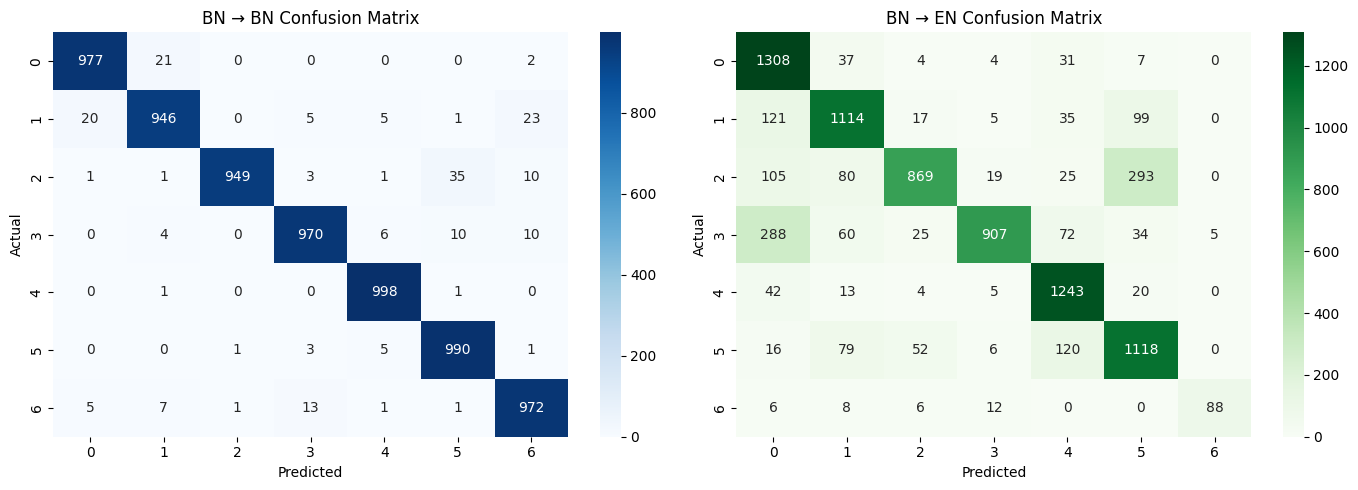

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm_bnbn = confusion_matrix(y_true_bnbn, y_pred_bnbn)
cm_bnen = confusion_matrix(y_true_bnen, y_pred_bnen)

fig, axes = plt.subplots(1,2, figsize=(14,5))

sns.heatmap(cm_bnbn, annot=True, fmt="d", cmap="Blues", ax=axes[0])
axes[0].set_title("BN → BN Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(cm_bnen, annot=True, fmt="d", cmap="Greens", ax=axes[1])
axes[1].set_title("BN → EN Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print("BN → BN Classification Report")
print(classification_report(y_true_bnbn, y_pred_bnbn))

print("\nBN → EN Classification Report")
print(classification_report(y_true_bnen, y_pred_bnen))

BN → BN Classification Report
              precision    recall  f1-score   support

           0       0.97      0.98      0.98      1000
           1       0.97      0.95      0.96      1000
           2       1.00      0.95      0.97      1000
           3       0.98      0.97      0.97      1000
           4       0.98      1.00      0.99      1000
           5       0.95      0.99      0.97      1000
           6       0.95      0.97      0.96      1000

    accuracy                           0.97      7000
   macro avg       0.97      0.97      0.97      7000
weighted avg       0.97      0.97      0.97      7000


BN → EN Classification Report
              precision    recall  f1-score   support

           0       0.69      0.94      0.80      1391
           1       0.80      0.80      0.80      1391
           2       0.89      0.62      0.73      1391
           3       0.95      0.65      0.77      1391
           4       0.81      0.94      0.87      1327
           5     

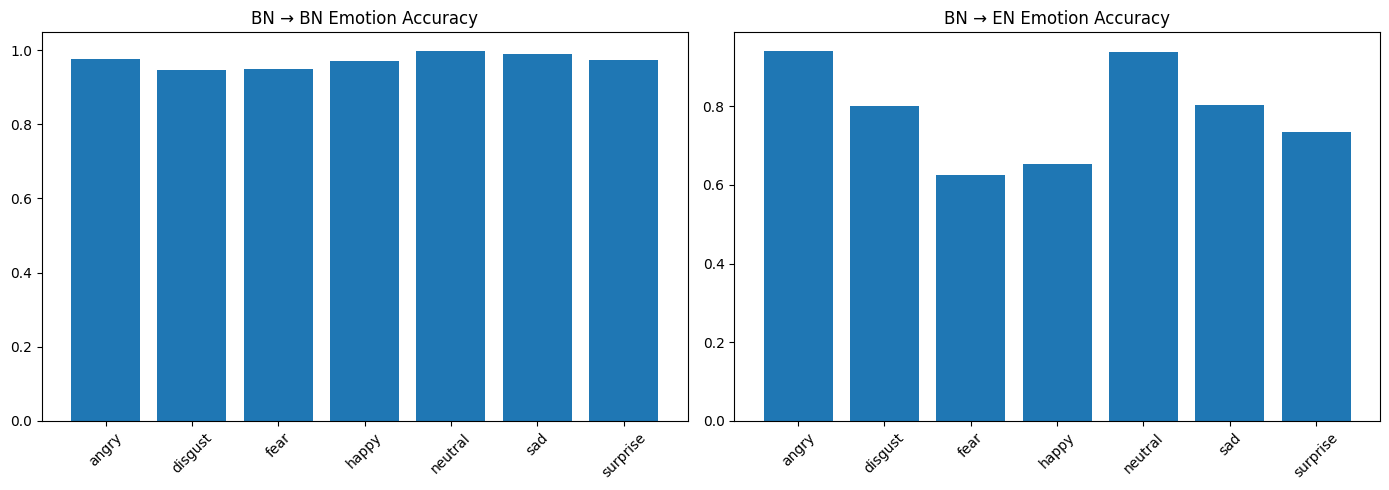

In [ ]:
per_emotion_bnbn = cm_bnbn.diagonal() / cm_bnbn.sum(axis=1)
per_emotion_bnen = cm_bnen.diagonal() / cm_bnen.sum(axis=1)

labels = encoder_cross.classes_

fig, axes = plt.subplots(1,2, figsize=(14,5))

axes[0].bar(labels, per_emotion_bnbn)
axes[0].set_title("BN → BN Emotion Accuracy")
axes[0].tick_params(axis='x', rotation=45)

axes[1].bar(labels, per_emotion_bnen)
axes[1].set_title("BN → EN Emotion Accuracy")
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

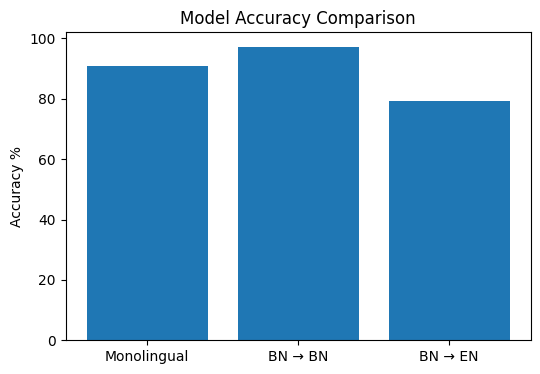

Monolingual: 90.77380952380952
BN→BN: 97.17142857142858
BN→EN: 79.11211616281838


In [ ]:
mono_acc = 90.77380952380952
acc_bnbn = (y_true_bnbn == y_pred_bnbn).mean()*100
acc_bnen = (y_true_bnen == y_pred_bnen).mean()*100

plt.figure(figsize=(6,4))

plt.bar(
    ["Monolingual", "BN → BN", "BN → EN"],
    [mono_acc, acc_bnbn, acc_bnen]
)

plt.ylabel("Accuracy %")
plt.title("Model Accuracy Comparison")
plt.show()

print("Monolingual:", mono_acc)
print("BN→BN:", acc_bnbn)
print("BN→EN:", acc_bnen)

In [ ]:
import os, pickle, numpy as np

SAVE_DIR = "/content/final_cross_lingual_master"
os.makedirs(SAVE_DIR, exist_ok=True)

model.save_pretrained(f"{SAVE_DIR}/model")
processor.save_pretrained(f"{SAVE_DIR}/processor")

with open(f"{SAVE_DIR}/encoder_cross.pkl","wb") as f:
    pickle.dump(encoder_cross,f)

np.save(f"{SAVE_DIR}/logits_bnbn.npy", preds_bnbn.predictions)
np.save(f"{SAVE_DIR}/logits_bnen.npy", preds_bnen.predictions)

print("Final master checkpoint saved locally")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Final master checkpoint saved locally


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!cp -r /content/final_cross_lingual_master /content/drive/MyDrive/

# save datasets to avoid future rebuild
!cp -r /content/SAVEEE_DATA /content/drive/MyDrive/
!cp -r /content/CRAMA-D_DATA /content/drive/MyDrive/
!cp -r /content/SUBESCO_BANGLA /content/drive/MyDrive/

print("Final pipeline backed up to Google Drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
^C
Final pipeline backed up to Google Drive
